# Домашнє завдання: ETL-пайплайни для аналітиків даних

Це ДЗ передбачене під виконання на локальній машині. Виконання з Google Colab буде суттєво ускладнене.

## Підготовка
1. Переконайтесь, що у вас встановлены необхідні бібліотеки:
   ```bash
   pip install sqlalchemy pymysql pandas matplotlib seaborn python-dotenv
   ```

2. Створіть файл `.env` з параметрами підключення до бази даних classicmodels. Базу даних ви можете отримати через

  - docker-контейнер згідно існтрукції в [документі](https://www.notion.so/hannapylieva/Docker-1eb94835849480c9b2e7f5dc22ee4df9), також відео інструкції присутні на платформі - уроки "MySQL бази, клієнт для роботи з БД, Docker і ChatGPT для запитів" та "Як встановити Docker для роботи з базами даних без терміналу"
  - або встановивши локально цю БД - для цього перегляньте урок "Опціонально. Встановлення MySQL та  БД Сlassicmodels локально".
  
  Приклад `.env` файлу ми створювали в лекції. Ось його обовʼязкове наповнення:
    ```
    DB_HOST=your_host
    DB_PORT=3306 або 3307 - той, який Ви налаштували
    DB_USER=your_username
    DB_PASSWORD=your_password
    DB_NAME=classicmodels
    ```
  Якщо ви створили цей файл під час перегляду лекції - **новий створювати не треба**. Замініть лише назву БД, або пропишіть назву в коді створення підключення (замість отримання назви цільової БД зі змінних оточення). Але переконайтесь, що до `.env` файл лежить в тій самій папці, що і цей ноутбук.

  **УВАГА!** НЕ копіюйте скрит для **створення** `.env` файлу. В лекції він наводиться для прикладу. І давалось пояснення, що в реальних проєктах ми НІКОЛИ не пишемо доступи до бази в коді. Копіювання скрипта для створення `.env` файлу сюди в ДЗ буде вважатись грубою помилкою і ми зніматимемо бали.

3. Налаштуйте підключення через SQLAlchemy до БД за прикладом в лекції.

Рекомендую вивести (відобразити) змінну engine після створення. Вона має бути не None! Якщо None - значить у Вас не підтягнулись налаштування з .env файла.

Ви також можете налаштувати параметри підключення до БД без .env файла, просто прописавши текстом в відповідних місцях. Це - не рекомендований підхід.

### Завдання 1: Створення таблиці курсів валют та API інтеграція (2 бали)

**Повторіть процедуру з лекції:** створіть таблицю для курсів валют, але вже в цій базі даних. Результатом має бути нова таблиця з курсами валют USD, EUR, UAH в БД (можна завантажити більше валют). Продемонструйте, що таблиця була додана, використовуючи SELECT.

Тобто тут ви можете прямо скопіювати код з лекції, внести необхідні зміни і запустити. Головне - отримати таблицю в БД classicmodels.

In [1]:
import os
import datetime

import requests

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

load_dotenv()

def create_connection():
    host = os.getenv("DB_HOST", "localhost")
    port = os.getenv("DB_PORT", "3306")
    user = os.getenv("DB_USER")
    password = os.getenv("DB_PASSWORD")
    database = os.getenv("DB_NAME")
    if not all([user, password, database]):
        raise ValueError("Не всі параметри БД задані в .env файлі!")

    engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}", pool_pre_ping=True)
    with engine.connect() as conn:
        conn.execute(text("SELECT 1"))
    print(f"✅ Підключення до БД успішне: {user}@{host}:{port}/{database}")
    return engine

engine = create_connection()
engine

def create_currency_table(engine):
    create_table_sql = text("""
        CREATE TABLE IF NOT EXISTS currency_rates (
            id INT AUTO_INCREMENT PRIMARY KEY,
            currency_code VARCHAR(3) NOT NULL,
            rate_to_usd DECIMAL(12, 6) NOT NULL,
            rate_date DATE NOT NULL,
            created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
            updated_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP ON UPDATE CURRENT_TIMESTAMP,
            INDEX idx_currency_date (currency_code, rate_date),
            UNIQUE KEY unique_currency_date (currency_code, rate_date)
        )
    """)
    with engine.connect() as conn:
        conn.execute(create_table_sql)
        conn.commit()
    print("✅ Таблиця currency_rates готова")

def fetch_exchange_rates(currencies=("USD", "EUR", "UAH", "GBP", "PLN")):
    response = requests.get("https://api.exchangerate-api.com/v4/latest/USD", timeout=15)
    response.raise_for_status()
    data = response.json()
    rates = {code: data["rates"][code] for code in currencies if code in data["rates"]}
    return rates, datetime.date.today()

def save_exchange_rates(engine, rates_dict, rate_date):
    insert_sql = text("""
        INSERT INTO currency_rates (currency_code, rate_to_usd, rate_date)
        VALUES (:currency, :rate, :date)
        ON DUPLICATE KEY UPDATE rate_to_usd = VALUES(rate_to_usd), updated_at = CURRENT_TIMESTAMP
    """)
    with engine.connect() as conn:
        with conn.begin():
            for currency, rate in rates_dict.items():
                conn.execute(insert_sql, {"currency": currency, "rate": rate, "date": rate_date})
    print(f"✅ Збережено {len(rates_dict)} курсів на {rate_date}")

✅ Підключення до БД успішне: root@localhost:3306/classicmodels


In [2]:
create_currency_table(engine)
rates, rate_date = fetch_exchange_rates()
print(f"Курси на {rate_date}:")
for currency, rate in rates.items():
    print(f"  1 USD = {rate:.4f} {currency}")
save_exchange_rates(engine, rates, rate_date)

pd.read_sql("SELECT currency_code, rate_to_usd, rate_date, created_at FROM currency_rates "
            "ORDER BY rate_date DESC, currency_code", engine)

✅ Таблиця currency_rates готова


Курси на 2026-11-08:
  1 USD = 1.0000 USD
  1 USD = 0.8960 EUR
  1 USD = 45.3800 UAH
  1 USD = 0.7480 GBP
  1 USD = 3.9400 PLN
✅ Збережено 5 курсів на 2026-11-08


,currency_code,rate_to_usd,rate_date,created_at
0,EUR,0.90,2026-11-08,2026-11-07 22:20:24
1,GBP,0.75,2026-11-08,2026-11-07 22:20:24
2,PLN,3.94,2026-11-08,2026-11-07 22:20:24
3,UAH,45.38,2026-11-08,2026-11-07 22:20:24
4,USD,1.00,2026-11-08,2026-11-07 22:20:24


# Завдання 2: Створення простого ETL пайплайну (7 балів)

В цьому завданні ми створимо повноцінний ETL процес для аналізу продажів ClassicModels.

Завдання обʼємне і оцінюється відповідно. Ви можете пропустити обчислення якихось з метрик, якщо відчуєте, що вже немає сил робити це завдання. Бал буде виставлено виходячи з виконаного обʼєму та його правильності.

## Що саме треба зробити:

### Extract (Витягування даних):
На цьому етапі треба витягнути дані з БД в pandas.DataFrame для подальшої обробки.
Які дані нам потрібні (кожен пункт - в окремий фрейм даних):
1. **дані про виконані замовлення за 2004 рік** - з'єднати таблиці orders, orderdetails, products, customers
2. **дані про продукти** - назви, категорії, ціни
3. **дані про курси валют** - використати дані з попереднього завдання

### Transform (Обробка даних):

#### 2.1 Додати розрахункові колонки до основної таблиці:
Додайте до DataFrame з продажами такі нові колонки:

- **`profit_per_item`** - прибуток з одного товару (використайте колонки: `priceEach` - `buyPrice`)
- **`total_profit`** - загальний прибуток з товарної позиції (використайте колонки: `profit_per_item` × `quantityOrdered`)
- **`total_amount_eur`** - сума в євро (використайте колонки: `total_amount` / `eur_rate`)

#### 2.2 Створити аналітичну таблицю по країнах (ТОП-5):
Згрупуйте дані по колонці **`country`** та обчисліть для кожної країни:

**Метрики для розрахунку:**
- **Кількість унікальних замовлень** - унікальні значення колонки `orderNumber`
- **Загальний дохід** - сума колонки `total_amount`
- **Загальний прибуток** - сума колонки `total_profit`
- **Кількість проданих товарів** - сума колонки `quantityOrdered`
- **Маржа прибутку (%)** - (`загальний прибуток` / `загальний дохід`) × 100

**Результат:** Таблиця з 5 найприбутковіших країн, відсортована за загальним доходом (від більшого до меншого).

#### 2.3 Створити аналітичну таблицю по продуктових лініях:
Згрупуйте дані по колонці **`productLine`** та обчисліть ті ж метрики:

**Метрики для розрахунку:**
- **Кількість унікальних замовлень** - унікальні значення колонки `orderNumber`
- **Загальний дохід** - сума колонки `total_amount`
- **Загальний прибуток** - сума колонки `total_profit`
- **Кількість проданих товарів** - сума колонки `quantityOrdered`
- **Маржа прибутку (%)** - (`загальний прибуток` / `загальний дохід`) × 100

**Результат:** Таблиця з усіма продуктовими лініями, відсортована за загальним доходом.

#### 2.4 Створити підсумкову інформацію (Executive Summary):
Розрахуйте загальні показники бізнесу за 2004 рік:

**Фінансові показники:**
- **Загальний дохід в доларах** - сума всієї колонки `total_amount`
- **Загальний дохід в євро** - сума всієї колонки `total_amount_eur`
- **Загальний прибуток в доларах** - сума всієї колонки `total_profit`
- **Загальна маржа прибутку (%)** - (`загальний прибуток` / `загальний дохід`) × 100
- **Середній розмір замовлення** - середнє значення колонки `total_amount`

**Операційні показники:**
- **Кількість унікальних замовлень** - унікальні значення колонки `orderNumber`
- **Кількість унікальних клієнтів** - унікальні значення колонки `customerName`
- **Період даних** - мінімальна та максимальна дата з колонки `orderDate`

**Топ показники:**
- **Найприбутковіша країна** - перший рядок з таблиці країн (колонка `country`)
- **Найприбутковіша продуктова лінія** - перший рядок з таблиці продуктів (колонка `productLine`)

### Load (Збереження результатів):
В цій частині ми зберігаємо результати наших обчислень.
Використайте приклади коду з лекцій та адаптуйте його під цей ETL процес.
Що Вам потрібно створити:

#### 3.1 Excel файл з трьома вкладками:
- **"Summary"** - підсумкова інформація у вигляді таблиці "Показник - Значення"
- **"Top_Countries"** - аналітика по топ-5 країнах
- **"Product_Lines"** - аналітика по всіх продуктових лініях

#### 3.2 Візуалізація:
- Створіть стовпчикову діаграму топ-5 країн за доходом.
- Створіть pie chart з відсотковим розподілом доходу в USD по продуктових лінійках.

## РЕКОМЕНДАЦІЇ ДО ВИКОНАННЯ:

### Покрокова стратегія виконання:
1. Спочатку протестуйте Extract просто в Jupyter notebook (без фукнції) - переконайтеся що SQL запит працює і повертає дані за 2004 рік
2. Потім протестуйте кожен Transform окремо - виведіть проміжні результати
3. Нарешті протестуйте Load - перевірте що файли створюються правильно  
4. Тільки після цього обгортайте все в функцію

### Як перевірити що все працює:
- Виводьте на екран, який етап зараз відбувається
- Виведіть кількість записів після кожного кроку
- Покажіть перші 5 рядків кожної аналітичної таблиці
- Перевірте що дати належать 2004 року
- Переконайтеся що маржа прибутку в розумних межах (0-50%)

In [3]:
def extract(engine, year=2004):
    print(f"📥 1. EXTRACT — дані за {year} рік")
    sales_query = text("""
        SELECT o.orderNumber, o.orderDate, o.status,
               c.customerName, c.country,
               p.productCode, p.productName, p.productLine, p.buyPrice,
               od.quantityOrdered, od.priceEach,
               od.quantityOrdered * od.priceEach AS total_amount
        FROM orders AS o
        JOIN orderdetails AS od ON od.orderNumber = o.orderNumber
        JOIN products AS p ON p.productCode = od.productCode
        JOIN customers AS c ON c.customerNumber = o.customerNumber
        WHERE o.status = 'Shipped'
          AND o.orderDate >= :date_from AND o.orderDate < :date_to
    """)
    sales = pd.read_sql(sales_query, engine, parse_dates=["orderDate"],
                        params={"date_from": f"{year}-01-01", "date_to": f"{year + 1}-01-01"})
    for col in ["buyPrice", "priceEach", "total_amount"]:
        sales[col] = sales[col].astype(float)

    products = pd.read_sql("SELECT productCode, productName, productLine, buyPrice, MSRP FROM products", engine)
    rates = pd.read_sql("""
        SELECT currency_code, rate_to_usd, rate_date
        FROM currency_rates
        WHERE rate_date = (SELECT MAX(rate_date) FROM currency_rates)
    """, engine)
    rates["rate_to_usd"] = rates["rate_to_usd"].astype(float)
    print(f"   продажі: {len(sales)} рядків | продукти: {len(products)} | курси: {len(rates)}")
    return sales, products, rates

sales, products_df, rates_df = extract(engine)
print("Роки в даних:", sorted(sales["orderDate"].dt.year.unique()), "| статуси:", sales["status"].unique().tolist())
sales.head()

📥 1. EXTRACT — дані за 2004 рік
   продажі: 1353 рядків | продукти: 110 | курси: 5
Роки в даних: [np.int32(2004)] | статуси: ['Shipped']


,orderNumber,orderDate,status,customerName,country,productCode,productName,productLine,buyPrice,quantityOrdered,priceEach,total_amount
0,10345,2004-11-25,Shipped,Atelier graphique,France,S24_2022,1938 Cadillac V-16 Presidential Limousine,Vintage Cars,20.61,43,38.98,"1,676.14"
1,10298,2004-09-27,Shipped,Atelier graphique,France,S18_2625,1936 Harley Davidson El Knucklehead,Motorcycles,24.23,32,60.57,"1,938.24"
2,10298,2004-09-27,Shipped,Atelier graphique,France,S10_2016,1996 Moto Guzzi 1100i,Motorcycles,68.99,39,105.86,"4,128.54"
3,10346,2004-11-29,Shipped,Signal Gift Stores,USA,S24_3969,1936 Mercedes Benz 500k Roadster,Vintage Cars,21.75,22,38.57,848.54
4,10278,2004-08-06,Shipped,Signal Gift Stores,USA,S24_3856,1956 Porsche 356A Coupe,Classic Cars,98.30,25,136.22,"3,405.50"


In [4]:
def add_columns(sales, rates):
    df = sales.copy()
    eur_per_usd = rates.loc[rates["currency_code"] == "EUR", "rate_to_usd"].iloc[0]
    eur_rate = 1 / eur_per_usd
    df["eur_rate"] = eur_rate
    df["profit_per_item"] = df["priceEach"] - df["buyPrice"]
    df["total_profit"] = df["profit_per_item"] * df["quantityOrdered"]
    df["total_amount_eur"] = df["total_amount"] / eur_rate
    return df

def group_metrics(df, by):
    table = df.groupby(by).agg(
        unique_orders=("orderNumber", "nunique"),
        total_revenue=("total_amount", "sum"),
        total_profit=("total_profit", "sum"),
        items_sold=("quantityOrdered", "sum"),
    )
    table["profit_margin_pct"] = table["total_profit"] / table["total_revenue"] * 100
    return table.sort_values("total_revenue", ascending=False).reset_index()

def make_summary(df, top_countries, product_lines):
    revenue, profit = df["total_amount"].sum(), df["total_profit"].sum()
    rows = [
        ("Загальний дохід, USD", round(revenue, 2)),
        ("Загальний дохід, EUR", round(df["total_amount_eur"].sum(), 2)),
        ("Загальний прибуток, USD", round(profit, 2)),
        ("Загальна маржа прибутку, %", round(profit / revenue * 100, 2)),
        ("Середній розмір замовлення (середнє total_amount), USD", round(df["total_amount"].mean(), 2)),
        ("Середній чек замовлення (дохід / кількість замовлень), USD", round(revenue / df["orderNumber"].nunique(), 2)),
        ("Кількість унікальних замовлень", int(df["orderNumber"].nunique())),
        ("Кількість унікальних клієнтів", int(df["customerName"].nunique())),
        ("Період даних", f"{df['orderDate'].min():%Y-%m-%d} — {df['orderDate'].max():%Y-%m-%d}"),
        ("Найприбутковіша країна", top_countries.loc[0, "country"]),
        ("Найприбутковіша продуктова лінія", product_lines.loc[0, "productLine"]),
        ("Курс: USD за 1 EUR", round(df["eur_rate"].iloc[0], 4)),
    ]
    return pd.DataFrame(rows, columns=["Показник", "Значення"])

def transform(sales, rates):
    print("🔧 2. TRANSFORM")
    df = add_columns(sales, rates)
    print(f"   2.1 додано колонки profit_per_item, total_profit, total_amount_eur (1 EUR = {df['eur_rate'].iloc[0]:.4f} USD)")
    countries = group_metrics(df, "country")
    top_countries = (countries.nlargest(5, "total_profit")
                     .sort_values("total_revenue", ascending=False).reset_index(drop=True))
    print(f"   2.2 ТОП-5 найприбутковіших країн із {len(countries)}")
    product_lines = group_metrics(df, "productLine")
    print(f"   2.3 продуктових ліній: {len(product_lines)}")
    summary = make_summary(df, top_countries, product_lines)
    print("   2.4 підсумок готовий")
    return df, top_countries, product_lines, summary

df_sales, top_countries, product_lines, summary = transform(sales, rates_df)
display(top_countries.head())
display(product_lines.head())
margins = pd.concat([top_countries["profit_margin_pct"], product_lines["profit_margin_pct"]])
print(f"Маржа в межах 0–50%: {margins.between(0, 50).all()} (від {margins.min():.1f}% до {margins.max():.1f}%)")
summary

🔧 2. TRANSFORM
   2.1 додано колонки profit_per_item, total_profit, total_amount_eur (1 EUR = 1.1161 USD)
   2.2 ТОП-5 найприбутковіших країн із 21
   2.3 продуктових ліній: 7
   2.4 підсумок готовий


,country,unique_orders,total_revenue,total_profit,items_sold,profit_margin_pct
0,USA,52,"1,485,054.44","597,654.15",16265,40.24
1,France,19,"506,660.01","211,528.15",5632,41.75
2,Spain,13,"392,816.48","156,131.39",4357,39.75
3,Australia,6,"204,213.18","78,176.66",2232,38.28
4,New Zealand,5,"195,592.89","78,147.87",2229,39.95


,productLine,unique_orders,total_revenue,total_profit,items_sold,profit_margin_pct
0,Classic Cars,93,"1,682,980.21","671,878.21",15424,39.92
1,Vintage Cars,85,"823,927.95","337,219.36",10487,40.93
2,Motorcycles,37,"527,243.84","222,485.41",5976,42.20
3,Trucks and Buses,39,"448,702.69","176,415.25",4853,39.32
4,Planes,32,"438,255.50","168,722.36",5439,38.50


Маржа в межах 0–50%: True (від 35.2% до 42.2%)


,Показник,Значення
0,"Загальний дохід, USD","4,300,602.99"
1,"Загальний дохід, EUR","3,853,340.28"
2,"Загальний прибуток, USD","1,723,682.41"
3,"Загальна маржа прибутку, %",40.08
4,Середній розмір замовлення (середнє total_amou...,"3,178.57"
5,Середній чек замовлення (дохід / кількість зам...,"29,659.33"
6,Кількість унікальних замовлень,145
7,Кількість унікальних клієнтів,87
8,Період даних,2004-01-02 — 2004-12-17
9,Найприбутковіша країна,USA


🚀 ETL-пайплайн ClassicModels за 2004 рік
📥 1. EXTRACT — дані за 2004 рік


   продажі: 1353 рядків | продукти: 110 | курси: 5
🔧 2. TRANSFORM
   2.1 додано колонки profit_per_item, total_profit, total_amount_eur (1 EUR = 1.1161 USD)
   2.2 ТОП-5 найприбутковіших країн із 21
   2.3 продуктових ліній: 7
   2.4 підсумок готовий
💾 3. LOAD


   Excel: reports\etl_report_2004.xlsx


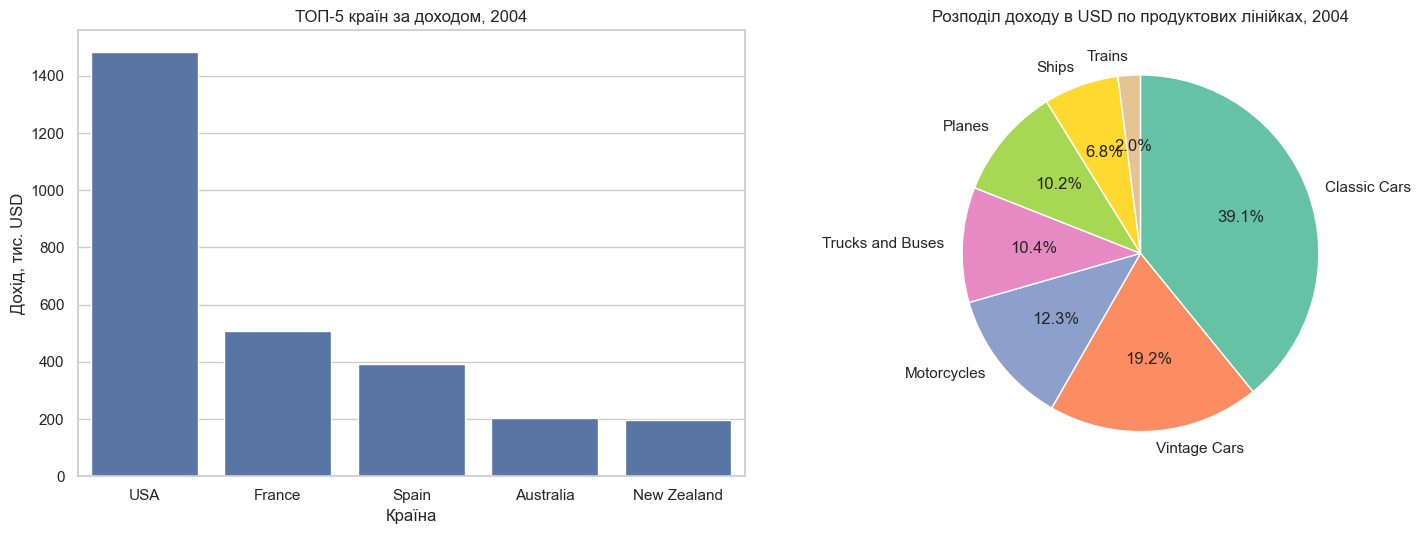

   Графіки: reports\etl_charts_2004.png
✅ ETL завершено
Вкладки у файлі: ['Summary', 'Top_Countries', 'Product_Lines']


In [5]:
def load(top_countries, product_lines, summary, output_dir="reports", year=2004):
    print("💾 3. LOAD")
    os.makedirs(output_dir, exist_ok=True)
    excel_path = os.path.join(output_dir, f"etl_report_{year}.xlsx")
    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        summary.to_excel(writer, sheet_name="Summary", index=False)
        top_countries.to_excel(writer, sheet_name="Top_Countries", index=False)
        product_lines.to_excel(writer, sheet_name="Product_Lines", index=False)
    print(f"   Excel: {excel_path}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.barplot(data=top_countries.assign(revenue_k=lambda d: d["total_revenue"] / 1000), x="country", y="revenue_k",
                color="#4C72B0", ax=axes[0])
    axes[0].set_title(f"ТОП-5 країн за доходом, {year}")
    axes[0].set_xlabel("Країна")
    axes[0].set_ylabel("Дохід, тис. USD")
    axes[1].pie(product_lines["total_revenue"], labels=product_lines["productLine"], autopct="%1.1f%%",
                startangle=90, counterclock=False, colors=sns.color_palette("Set2", len(product_lines)))
    axes[1].set_title(f"Розподіл доходу в USD по продуктових лінійках, {year}")
    plt.tight_layout()
    chart_path = os.path.join(output_dir, f"etl_charts_{year}.png")
    fig.savefig(chart_path, dpi=120)
    plt.show()
    print(f"   Графіки: {chart_path}")
    return excel_path

def run_etl(engine, year=2004, output_dir="reports"):
    print(f"🚀 ETL-пайплайн ClassicModels за {year} рік")
    sales, products, rates = extract(engine, year)
    df, top_countries, product_lines, summary = transform(sales, rates)
    excel_path = load(top_countries, product_lines, summary, output_dir, year)
    print("✅ ETL завершено")
    return df, top_countries, product_lines, summary, excel_path

df_sales, top_countries, product_lines, summary, excel_path = run_etl(engine)
print("Вкладки у файлі:", pd.ExcelFile(excel_path).sheet_names)

**Висновки**

- Виконаних (статус `Shipped`) замовлень за 2004 рік — **145**: 1 353 товарні позиції, 87 клієнтів, дати від 2004-01-02 до 2004-12-17.
- Дохід — **\$4 300 602.99**, прибуток — **\$1 723 682.41**, маржа — **40.08 %**. Суму в євро ноутбук рахує за курсом на день запуску (див. Summary).
- ТОП-5 країн: **USA, France, Spain, Australia, New Zealand**. США дають 34.5 % доходу року.
- Найбільша продуктова лінія — **Classic Cars** (\$1.68 млн, 39 % доходу). Найвища маржа — у Motorcycles (42.2 %), найнижча — у Trains (35.2 %).
- Курс у таблиці currency_rates — «EUR за 1 USD». Тому eur_rate = 1 / цей курс («USD за 1 EUR»), і `total_amount / eur_rate` дає суму в євро, як вимагає умова.
- Маржа всіх країн і лінійок — від 35 % до 42 %, тобто в розумних межах.
- Файли: `reports/etl_report_2004.xlsx` (вкладки Summary, Top_Countries, Product_Lines) і `reports/etl_charts_2004.png`.